                                         Healthcare Insurance Analysis

Problem statement:
A significant public health concern is the rising cost of healthcare. Therefore, it's crucial 
to be able to predict future costs and gain a solid understanding of their causes. The 
insurance industry must also take this analysis seriously. This analysis may be used by 
healthcare insurance providers to make a variety of strategic and tactical decisions.

Objective:
The objective of this project is to predict patients’ healthcare costs and to identify factors 
contributing to this prediction. It will also be useful to learn the interdependencies of 
different factors and comprehend the significance of various tools at various stages of 
the healthcare cost prediction process

In [404]:
### Importing Necessary Libraries
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import date
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from scipy.stats import f_oneway
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.base import clone

In [405]:
# Setting up the project directory and data paths
PROJECT_DIR="/Users/nithi/Desktop/Renu/Data Science/Capstone Projects/HealthCare Insurance Analysis"
DATA_DIR=os.path.join(PROJECT_DIR, "Capstone _1")
print(f"Using the data directory {DATA_DIR}")
hosp_path = os.path.join(DATA_DIR,"Hospitalisation details.csv")
exam_path = os.path.join(DATA_DIR, "Medical Examinations.csv")
names_path = os.path.join(DATA_DIR, "Names.xlsx")


Using the data directory /Users/nithi/Desktop/Renu/Data Science/Capstone Projects/HealthCare Insurance Analysis\Capstone _1


In [406]:
# Reading the datasets
hosp_df = pd.read_csv(hosp_path)
exam_df = pd.read_csv(exam_path)
names_df = pd.read_excel(names_path)    

In [407]:
##Analysis of the Hospitalisation datasets
print("Hospitalisation Details Dataset:")
print(hosp_df.head())
print("Hospitalisation Details Dataset Info:", hosp_df.info())
print("Hospitalisation Details Dataset shape:", hosp_df.shape)

Hospitalisation Details Dataset:
  Customer ID  year month  date  children  charges Hospital tier City tier  \
0      Id2335  1992   Jul     9         0   563.84      tier - 2  tier - 3   
1      Id2334  1992   Nov    30         0   570.62      tier - 2  tier - 1   
2      Id2333  1993   Jun    30         0   600.00      tier - 2  tier - 1   
3      Id2332  1992   Sep    13         0   604.54      tier - 3  tier - 3   
4      Id2331  1998   Jul    27         0   637.26      tier - 3  tier - 3   

  State ID  
0    R1013  
1    R1013  
2    R1013  
3    R1013  
4    R1013  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    2343 non-null   object 
 1   year           2343 non-null   object 
 2   month          2343 non-null   object 
 3   date           2343 non-null   int64  
 4   children       2343 non-null   int64  
 5   c

Hospitalisation dataset contains 2343 rows and 9 columns.There are no null values as non-null count is same for all columns. It contains year,month and date of patient DOB which can be used to calculate age. But year and month are object datatypes which needs to be changed to number.


In [408]:
## Checcking unique values in the object columns
hosp_df['year'].unique(), hosp_df['month'].unique(), hosp_df['date'].unique(), hosp_df['Hospital tier'].unique(), hosp_df['City tier'].unique(), hosp_df['State ID'].unique()

(array(['1992', '1993', '1998', '2001', '1995', '2002', '1997', '1999',
        '1996', '2004', '2000', '1994', '2003', '1989', '1991', '1988',
        '1990', '1987', '1986', '1981', '1985', '1984', '1983', '1982',
        '1980', '1979', '1977', '1978', '1974', '1973', '1972', '1975',
        '1971', '1970', '1969', '1976', '1968', '1966', '1965', '1967',
        '1962', '1963', '1964', '?', '1961', '1960', '1959', '1958'],
       dtype=object),
 array(['Jul', 'Nov', 'Jun', 'Sep', 'Dec', '?', 'Aug', 'Oct'], dtype=object),
 array([ 9, 30, 13, 27, 20,  1,  4, 29, 12, 26, 14, 19, 22, 28, 18,  7,  5,
        17, 24,  6, 11, 15, 25, 10,  2, 16,  8, 21,  3, 23]),
 array(['tier - 2', 'tier - 3', '?', 'tier - 1'], dtype=object),
 array(['tier - 3', 'tier - 1', 'tier - 2', '?'], dtype=object),
 array(['R1013', 'R1012', 'R1011', 'R1015', 'R1019', 'R1016', 'R1018',
        'R1025', 'R1024', 'R1023', 'R1014', 'R1021', 'R1017', 'R1020',
        'R1026', '?', 'R1022'], dtype=object))

There are some invalid values in the data checking for number of records with invalid values 

In [409]:
hosp_df['year'].value_counts(), hosp_df['month'].value_counts(), hosp_df['date'].value_counts(),hosp_df['Hospital tier'].value_counts(), hosp_df['City tier'].value_counts(), hosp_df['State ID'].value_counts()

(year
 2004    100
 2003     85
 1988     60
 1972     60
 1974     57
 1970     57
 1975     56
 1992     56
 1994     55
 2002     55
 1976     55
 1971     55
 1997     55
 1969     54
 1995     53
 1993     53
 1981     53
 1999     52
 1979     51
 1985     51
 1978     51
 1965     51
 1962     50
 1991     50
 1982     50
 2001     49
 1968     49
 1990     48
 1963     48
 1966     48
 2000     47
 1998     47
 1980     47
 1984     46
 1983     45
 1989     45
 1973     45
 1964     45
 1996     44
 1967     44
 1986     43
 1977     43
 1987     42
 1961     23
 1959     23
 1960     23
 1958     22
 ?         2
 Name: count, dtype: int64,
 month
 Sep    369
 Dec    344
 Aug    342
 Jul    342
 Oct    335
 Nov    320
 Jun    288
 ?        3
 Name: count, dtype: int64,
 date
 6     99
 29    97
 22    92
 12    92
 9     88
 28    88
 25    87
 10    85
 14    85
 17    84
 4     83
 5     83
 21    83
 27    80
 11    78
 24    78
 30    74
 2     73
 1     73
 19    72
 13  

In [410]:
hosp_df[(hosp_df['year'] == '?') | (hosp_df['month'] == '?') | (hosp_df['Hospital tier'] == '?') | (hosp_df['City tier'] == '?') | (hosp_df['State ID'] == '?') ]

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID
11,Id2324,1999,Dec,26,0,700.00,?,tier - 3,R1013
13,Id2322,2002,?,19,0,750.00,tier - 3,tier - 1,R1012
17,Id2318,1996,?,18,0,770.38,tier - 3,?,R1012
544,Id1793,1995,Dec,1,3,4827.90,tier - 1,tier - 2,?
1049,Id1289,?,Jul,24,0,8534.67,tier - 2,tier - 3,R1024
1052,Id1286,?,Dec,12,1,8547.69,tier - 2,tier - 1,R1013
2172,Id170,2000,Sep,5,1,37165.16,tier - 1,tier - 3,?
2340,Id3,1970,?,11,3,60021.40,tier - 1,tier - 1,R1012


The number of records with missing data is significantly less marking it as Nan and will drop them after merging with other datasets and checking percentage of missing values in the merged dataset.



In [411]:
for col in ['year', 'month', 'Hospital tier', 'City tier', 'State ID']:
    hosp_df[col] = hosp_df[col].replace('?', np.nan)

In [412]:
hosp_df[(hosp_df['year'] == '?') | (hosp_df['month'] == '?') | (hosp_df['Hospital tier'] == '?') | (hosp_df['City tier'] == '?') | (hosp_df['State ID'] == '?') ]

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID


In [413]:
## Changing month to number
hosp_df['month'] = pd.to_datetime(hosp_df['month'],format='%b',errors='coerce').dt.month
hosp_df['month'].unique()

array([ 7., 11.,  6.,  9., 12., nan,  8., 10.])

In [414]:
## Converting year and month to numeric
for col in ['month','year']:
    hosp_df[col]=pd.to_numeric(hosp_df[col],errors='coerce')
    hosp_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    2343 non-null   object 
 1   year           2341 non-null   object 
 2   month          2340 non-null   float64
 3   date           2343 non-null   int64  
 4   children       2343 non-null   int64  
 5   charges        2343 non-null   float64
 6   Hospital tier  2342 non-null   object 
 7   City tier      2342 non-null   object 
 8   State ID       2341 non-null   object 
dtypes: float64(2), int64(2), object(5)
memory usage: 164.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    2343 non-null   object 
 1   year           2341 non-null   float64
 2   month          2340 non-null   float64
 3   date           

Analysis and Cleaning of Medical Examinations Dataset

In [415]:
#Analysis of the Medical Examinations dataset
print("Medical Examinations Dataset:")
print(exam_df.head())   
print("Medical Examinations Dataset Info:", exam_df.info())
print("Medical Examinations Dataset shape:", exam_df.shape)


Medical Examinations Dataset:
  Customer ID     BMI  HBA1C Heart Issues Any Transplants Cancer history  \
0         Id1  47.410   7.47           No              No             No   
1         Id2  30.360   5.77           No              No             No   
2         Id3  34.485  11.87          yes              No             No   
3         Id4  38.095   6.05           No              No             No   
4         Id5  35.530   5.45           No              No             No   

  NumberOfMajorSurgeries smoker  
0       No major surgery    yes  
1       No major surgery    yes  
2                      2    yes  
3       No major surgery    yes  
4       No major surgery    yes  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2335 entries, 0 to 2334
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             2335 non-null   object 
 1   BMI                     2335 non-null  

In [416]:
exam_df['Heart Issues'].unique(), exam_df['Any Transplants'].unique(), exam_df['Cancer history'].unique(), exam_df['NumberOfMajorSurgeries'].unique(), exam_df['smoker'].unique(), exam_df['BMI'].unique(),exam_df['HBA1C'].unique()

(array(['No', 'yes'], dtype=object),
 array(['No', 'yes'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['No major surgery', '2', '3', '1'], dtype=object),
 array(['yes', 'No', '?'], dtype=object),
 array([47.41 , 30.36 , 34.485, ..., 17.82 , 17.07 , 17.58 ]),
 array([ 7.47,  5.77, 11.87,  6.05,  5.45,  6.59,  6.07,  7.93,  9.58,
        10.79,  5.96, 11.9 ,  8.41,  7.02,  7.59, 11.32,  7.67,  7.29,
         4.72, 11.41, 11.5 ,  6.22, 11.38,  7.89,  4.38,  7.01, 11.88,
         5.19,  6.74,  8.44,  8.71,  5.08,  6.86,  5.95,  6.09, 11.75,
         7.37, 11.91,  6.52,  5.14,  4.19, 11.68,  6.98,  8.34,  8.49,
         5.34,  4.43,  4.47,  4.82,  5.51, 10.87,  9.34,  5.03, 11.05,
        11.95,  7.72,  5.75, 11.89,  6.2 , 10.61,  6.04,  9.33, 11.47,
         8.8 ,  8.68,  6.12,  5.4 ,  4.36,  9.77,  4.25,  4.76,  7.96,
        10.92, 11.51,  5.99, 11.57,  6.67,  9.2 ,  5.11,  4.03,  4.23,
         4.06,  4.68,  4.34, 10.51,  5.84,  5.41,  6.06,  4.22,  5.12,
         4.57, 

In [417]:
exam_df[(exam_df['smoker']=='?')]

,Customer ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker
559,Id560,23.980,4.90,No,No,No,No major surgery,?
634,Id635,25.175,4.96,No,yes,No,1,?


In [418]:
exam_df['smoker'] = exam_df['smoker'].replace('?', np.nan)
exam_df[(exam_df['smoker']=='?')]

,Customer ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker


In [419]:
#Converting number of major surgeries to numeric
exam_df['NumberOfMajorSurgeries']=exam_df['NumberOfMajorSurgeries'].replace('No major surgery','0')
exam_df['NumberOfMajorSurgeries']=pd.to_numeric(exam_df['NumberOfMajorSurgeries'],errors='coerce')
exam_df['NumberOfMajorSurgeries'].unique()


array([0, 2, 3, 1])

Analysis and cleaning of Patient Name Dataset

In [420]:
#Analysis of the Patient Names dataset
print("Patient Names Dataset:")
print(names_df.head())
print("Patient Names Dataset Info:", names_df.info())   


Patient Names Dataset:
  Customer ID                    name
0         Id1       Hawks, Ms.  Kelly
1         Id2  Lehner, Mr.  Matthew D
2         Id3           Lu, Mr.  Phil
3         Id4    Osborne, Ms.  Kelsey
4         Id5    Kadala, Ms.  Kristyn
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2335 entries, 0 to 2334
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Customer ID  2335 non-null   object
 1   name         2335 non-null   object
dtypes: object(2)
memory usage: 36.6+ KB
Patient Names Dataset Info: None


Merging the datasets

In [421]:
hosp_exam_df = pd.merge(hosp_df, exam_df, on='Customer ID', how='left')
print("Merged Dataset Info:", hosp_exam_df.info())
print("Merged Dataset shape:", hosp_exam_df.shape)
hosp_exam_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             2343 non-null   object 
 1   year                    2341 non-null   float64
 2   month                   2340 non-null   float64
 3   date                    2343 non-null   int64  
 4   children                2343 non-null   int64  
 5   charges                 2343 non-null   float64
 6   Hospital tier           2342 non-null   object 
 7   City tier               2342 non-null   object 
 8   State ID                2341 non-null   object 
 9   BMI                     2335 non-null   float64
 10  HBA1C                   2335 non-null   float64
 11  Heart Issues            2335 non-null   object 
 12  Any Transplants         2335 non-null   object 
 13  Cancer history          2335 non-null   object 
 14  NumberOfMajorSurgeries  2335 non-null   

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker
0,Id2335,1992.0,7.0,9,0,563.84,tier - 2,tier - 3,R1013,17.58,4.51,No,No,No,1.0,No
1,Id2334,1992.0,11.0,30,0,570.62,tier - 2,tier - 1,R1013,17.60,4.39,No,No,No,1.0,No
2,Id2333,1993.0,6.0,30,0,600.00,tier - 2,tier - 1,R1013,16.47,6.35,No,No,Yes,1.0,No
3,Id2332,1992.0,9.0,13,0,604.54,tier - 3,tier - 3,R1013,17.70,6.28,No,No,No,1.0,No
4,Id2331,1998.0,7.0,27,0,637.26,tier - 3,tier - 3,R1013,22.34,5.57,No,No,No,1.0,No


In [422]:
#Merging names dataset with the merged hospitalisation and examination datasets 
hosp_exam_names_df = pd.merge(hosp_exam_df, names_df, on='Customer ID', how='left')
print("Merged Dataset with Names Info:", hosp_exam_names_df.info())
print("Merged Dataset with Names shape:", hosp_exam_names_df.shape)
hosp_exam_names_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2343 entries, 0 to 2342
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             2343 non-null   object 
 1   year                    2341 non-null   float64
 2   month                   2340 non-null   float64
 3   date                    2343 non-null   int64  
 4   children                2343 non-null   int64  
 5   charges                 2343 non-null   float64
 6   Hospital tier           2342 non-null   object 
 7   City tier               2342 non-null   object 
 8   State ID                2341 non-null   object 
 9   BMI                     2335 non-null   float64
 10  HBA1C                   2335 non-null   float64
 11  Heart Issues            2335 non-null   object 
 12  Any Transplants         2335 non-null   object 
 13  Cancer history          2335 non-null   object 
 14  NumberOfMajorSurgeries  2335 non-null   

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name
0,Id2335,1992.0,7.0,9,0,563.84,tier - 2,tier - 3,R1013,17.58,4.51,No,No,No,1.0,No,"German, Mr. Aaron K"
1,Id2334,1992.0,11.0,30,0,570.62,tier - 2,tier - 1,R1013,17.60,4.39,No,No,No,1.0,No,"Rosendahl, Mr. Evan P"
2,Id2333,1993.0,6.0,30,0,600.00,tier - 2,tier - 1,R1013,16.47,6.35,No,No,Yes,1.0,No,"Albano, Ms. Julie"
3,Id2332,1992.0,9.0,13,0,604.54,tier - 3,tier - 3,R1013,17.70,6.28,No,No,No,1.0,No,"Riveros Gonzalez, Mr. Juan D. Sr."
4,Id2331,1998.0,7.0,27,0,637.26,tier - 3,tier - 3,R1013,22.34,5.57,No,No,No,1.0,No,"Brietzke, Mr. Jordan"


Calculating Age of Patient from year,month and day columns

In [423]:
hosp_exam_names_df['DoB'] = pd.to_datetime(dict(year=hosp_exam_names_df['year']
                                                    , month=hosp_exam_names_df['month'].fillna(1).astype('Int64')
                                                    , day=hosp_exam_names_df['date'].fillna(1).astype('Int64')),
                                              errors='coerce')
# Calculate age from the date of birth
today = pd.to_datetime(date.today())
hosp_exam_names_df['age'] = (today.year - hosp_exam_names_df['DoB'].dt.year) - (
    (today.month < (hosp_exam_names_df['DoB'].dt.month)) | ((today.month == hosp_exam_names_df['DoB'].dt.month) & (today.day < hosp_exam_names_df['DoB'].dt.day))
)   
# Display the updated DataFrame with age
hosp_exam_names_df[['Customer ID', 'DoB', 'age']].head()

,Customer ID,DoB,age
0,Id2335,1992-07-09,33.0
1,Id2334,1992-11-30,32.0
2,Id2333,1993-06-30,32.0
3,Id2332,1992-09-13,32.0
4,Id2331,1998-07-27,27.0


In [424]:
    
hosp_exam_names_df[(hosp_exam_names_df['year'].isna())].head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,HBA1C,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name,DoB,age
1049,Id1289,NaN,7.0,24,0,8534.67,tier - 2,tier - 3,R1024,24.32,11.56,yes,No,No,1.0,No,"Levine, Ms. Annie J.",NaT,NaN
1052,Id1286,NaN,12.0,12,1,8547.69,tier - 2,tier - 1,R1013,29.37,8.01,yes,No,No,1.0,No,"Ainsley, Ms. Katie M.",NaT,NaN


Calculating gender from salutations in name column

In [425]:
hosp_exam_names_df['salutation'] = hosp_exam_names_df['name'].str.split(',').str[1].str.strip().str.split().str[0]

print(hosp_exam_names_df[['name', 'salutation']])
print(hosp_exam_names_df['salutation'].unique())
# Mapping salutations to gender
salutation_to_gender = {
    "Mr.": "Male",
    "Ms.": "Female",
    "Mrs.": "Female" 
}

hosp_exam_names_df['gender'] = hosp_exam_names_df['salutation'].map(salutation_to_gender).fillna("Unknown")



                                    name salutation
0                   German, Mr.  Aaron K        Mr.
1                 Rosendahl, Mr.  Evan P        Mr.
2                     Albano, Ms.  Julie        Ms.
3     Riveros Gonzalez, Mr.  Juan D. Sr.        Mr.
4                  Brietzke, Mr.  Jordan        Mr.
...                                  ...        ...
2338                Kadala, Ms.  Kristyn        Ms.
2339                Osborne, Ms.  Kelsey        Ms.
2340                       Lu, Mr.  Phil        Mr.
2341              Lehner, Mr.  Matthew D        Mr.
2342                   Hawks, Ms.  Kelly        Ms.

[2343 rows x 2 columns]
['Mr.' 'Ms.' 'Mrs.' nan]


Checking for the percentage of missing values in columns and delete such rows if they do 
not contain significant information

In [426]:
percent_missing_per_col = hosp_exam_names_df.isna().mean() * 100
print(percent_missing_per_col)


Customer ID               0.000000
year                      0.085361
month                     0.128041
date                      0.000000
children                  0.000000
charges                   0.000000
Hospital tier             0.042680
City tier                 0.042680
State ID                  0.085361
BMI                       0.341443
HBA1C                     0.341443
Heart Issues              0.341443
Any Transplants           0.341443
Cancer history            0.341443
NumberOfMajorSurgeries    0.341443
smoker                    0.426803
name                      0.341443
DoB                       0.085361
age                       0.085361
salutation                0.341443
gender                    0.000000
dtype: float64


Here critical columns are Customer ID and charges both doesnt contain any null values. As missing percentages in eacch columns are very less we can drop these records.

In [427]:
mask_trivial_row = hosp_exam_names_df.isna().any(axis=1)
percent_rows_trivial = mask_trivial_row.mean() * 100
print(f"Percentage of rows with trivial values: {percent_rows_trivial:.2f}%")
critical_cols={'customer ID','charges'}
non_critical_cols=set(hosp_exam_names_df.columns)-critical_cols 
merged_df=hosp_exam_names_df.dropna(subset=non_critical_cols).reset_index(drop=True)
print("Shape before dropping trivial rows:", hosp_exam_names_df.shape)
print("Shape after dropping trivial rows:", merged_df.shape)


Percentage of rows with trivial values: 0.77%
Shape before dropping trivial rows: (2343, 21)
Shape after dropping trivial rows: (2325, 21)


In [428]:
merged_df.head()

,Customer ID,year,month,date,children,charges,Hospital tier,City tier,State ID,BMI,...,Heart Issues,Any Transplants,Cancer history,NumberOfMajorSurgeries,smoker,name,DoB,age,salutation,gender
0,Id2335,1992.0,7.0,9,0,563.84,tier - 2,tier - 3,R1013,17.58,...,No,No,No,1.0,No,"German, Mr. Aaron K",1992-07-09,33.0,Mr.,Male
1,Id2334,1992.0,11.0,30,0,570.62,tier - 2,tier - 1,R1013,17.60,...,No,No,No,1.0,No,"Rosendahl, Mr. Evan P",1992-11-30,32.0,Mr.,Male
2,Id2333,1993.0,6.0,30,0,600.00,tier - 2,tier - 1,R1013,16.47,...,No,No,Yes,1.0,No,"Albano, Ms. Julie",1993-06-30,32.0,Ms.,Female
3,Id2332,1992.0,9.0,13,0,604.54,tier - 3,tier - 3,R1013,17.70,...,No,No,No,1.0,No,"Riveros Gonzalez, Mr. Juan D. Sr.",1992-09-13,32.0,Mr.,Male
4,Id2331,1998.0,7.0,27,0,637.26,tier - 3,tier - 3,R1013,22.34,...,No,No,No,1.0,No,"Brietzke, Mr. Jordan",1998-07-27,27.0,Mr.,Male


In [429]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2325 entries, 0 to 2324
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Customer ID             2325 non-null   object        
 1   year                    2325 non-null   float64       
 2   month                   2325 non-null   float64       
 3   date                    2325 non-null   int64         
 4   children                2325 non-null   int64         
 5   charges                 2325 non-null   float64       
 6   Hospital tier           2325 non-null   object        
 7   City tier               2325 non-null   object        
 8   State ID                2325 non-null   object        
 9   BMI                     2325 non-null   float64       
 10  HBA1C                   2325 non-null   float64       
 11  Heart Issues            2325 non-null   object        
 12  Any Transplants         2325 non-null   object  

Plotting the distribution of costs using a histogram, box and whisker plot, and swarm plot.

Text(0.5, 1.0, 'Swarmplot showing distribution of healthcare charges')

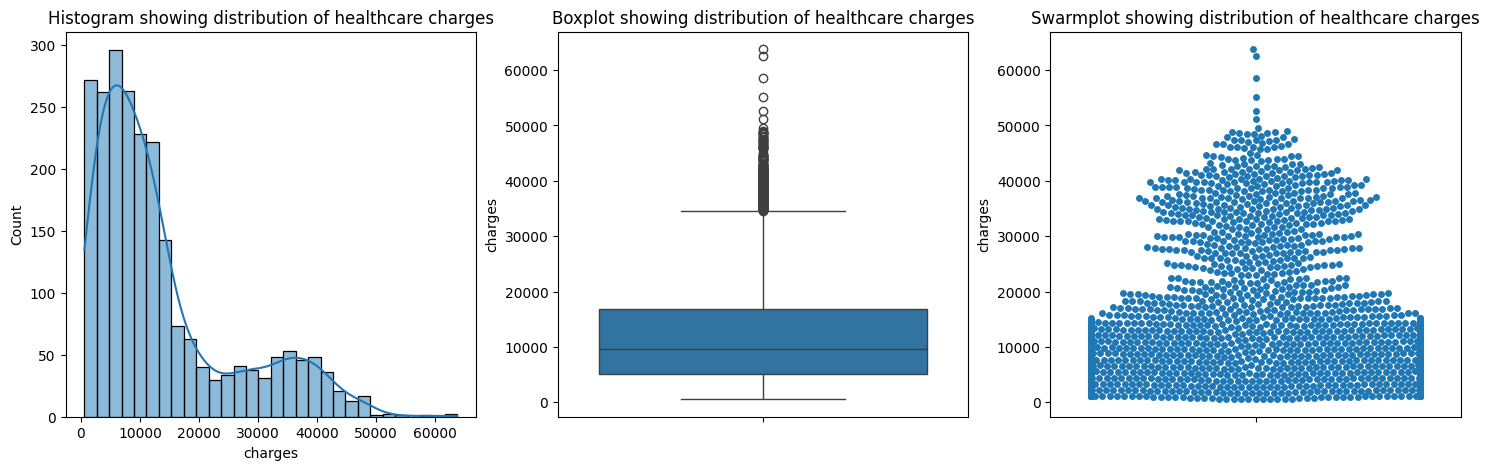

In [430]:
fig, axes = plt.subplots(1,3, figsize=(18,5))
sns.histplot(merged_df['charges'], bins=30, kde=True,ax=axes[0])
axes[0].set_title('Histogram showing distribution of healthcare charges') 
sns.boxplot(y=merged_df['charges'], ax=axes[1])
axes[1].set_title('Boxplot showing distribution of healthcare charges')
sns.swarmplot(y=merged_df['charges'], ax=axes[2])
axes[2].set_title('Swarmplot showing distribution of healthcare charges')

<Axes: xlabel='Hospital tier', ylabel='charges'>

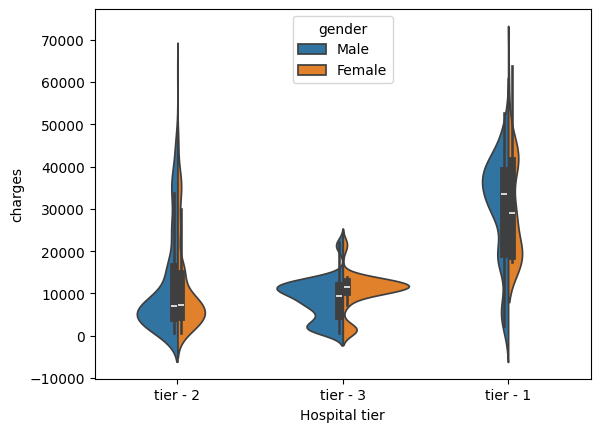

In [431]:
sns.violinplot(y=merged_df['charges'],x='Hospital tier',hue='gender',data=merged_df,split=True)

<Axes: xlabel='Hospital tier', ylabel='charges'>

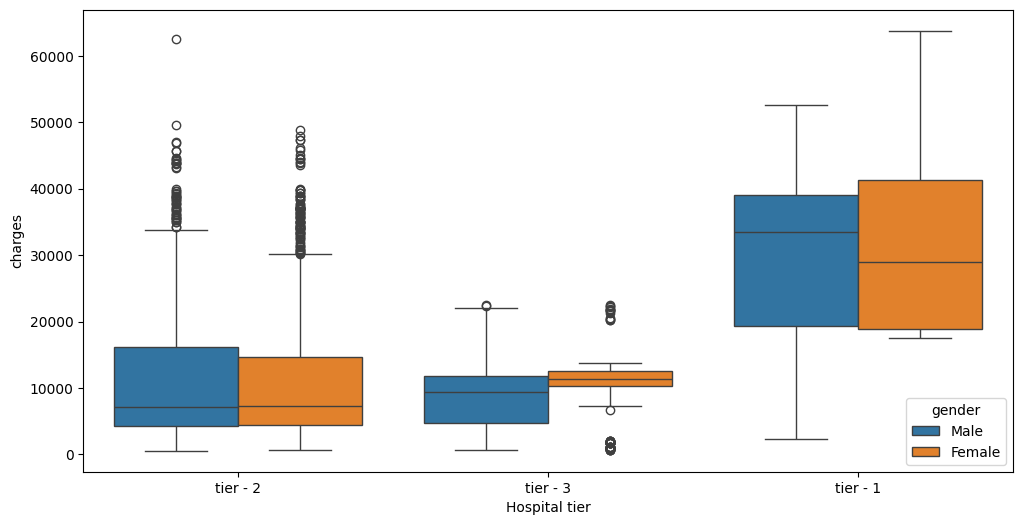

In [432]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Hospital tier', y='charges', hue='gender', data=merged_df)

Inferences:
1. Tier-1 hospital charges are very high with no outliers and cost is distributed acroos a wide range indicating chnages in the charges incurred.
2. Tier-2 hospital charges are less compared to Tier-1 and has many outliers indicating there are patients who incurred high charges.
3. Tier -3 hospitals are very less but there are outliers for female patients.
4. Gender wise in tier 1 males have high median costs compared to female, where in tier 3 females have hig median charges(can be due to high outliers).
   Median costs for both genders are almost same in tier-2 hospitals.
5. Hospital charges increases as hospital tiers becomes high.

Hospital tier
tier - 1    32097.435
tier - 2     7168.760
tier - 3    10676.830
Name: charges, dtype: float64


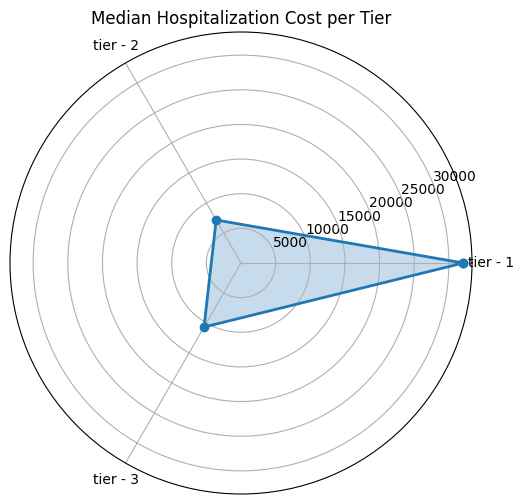

In [433]:
median_charges= merged_df.groupby('Hospital tier')['charges'].median()
print(median_charges)
categories = median_charges.index
values = median_charges.values

# Repeat first value to close the radar chart
values = np.append(values, values[0])
angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False)
angles = np.append(angles, angles[0])

plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)
ax.plot(angles, values, 'o-', linewidth=2)
ax.fill(angles, values, alpha=0.25)
ax.set_thetagrids(angles[:-1] * 180/np.pi, categories)
ax.set_title("Median Hospitalization Cost per Tier")
plt.show()


From the above Radar chart tier-1 has highest median charges. Tier 2 hospitals have median charges close to 5000 indicating they are affordable.Tier 3 hospitals have median charges in between tier1 and tier 2. From this we can infer tiering strongly impacts affordability and could influence healthcare decision-making.

In [434]:
freq_table = pd.crosstab(merged_df['City tier'], merged_df['Hospital tier'])
print(freq_table)

Hospital tier  tier - 1  tier - 2  tier - 3
City tier                                  
tier - 1             85       403       241
tier - 2            106       479       222
tier - 3            109       452       228


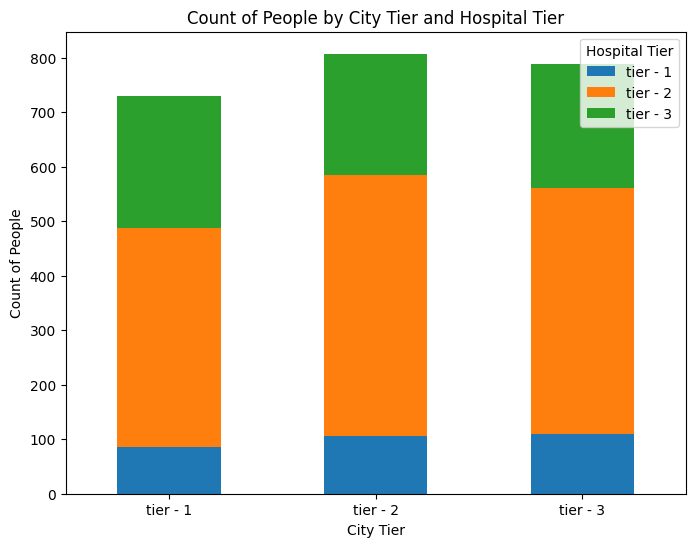

In [435]:
freq_table.plot(kind='bar', stacked=True, figsize=(8,6))
plt.title('Count of People by City Tier and Hospital Tier')
plt.xlabel('City Tier')
plt.ylabel('Count of People')
plt.legend(title='Hospital Tier')
plt.xticks(rotation=0)
plt.show()

From the above table we can see that in all city tiers number of people visiting tier 1 hospitals are very less indicating tier-1 hospitals are not affordable to majority of people. Also number of people who visited hospital in tier 1 city is less compared to tier 2 and toer 3 with tier 2 having the highest number of people.

Splitting data into numerical and categorical columns.

In [436]:
numcols = merged_df.select_dtypes(include=np.number)
#drop year, month, date as age is already calculated from these features
numcols=numcols.drop(['year','month','date'],axis=1,errors='ignore')
print(numcols.columns)
catcols = merged_df.select_dtypes(include=['object'])
print(catcols.columns)

Index(['children', 'charges', 'BMI', 'HBA1C', 'NumberOfMajorSurgeries', 'age'], dtype='object')
Index(['Customer ID', 'Hospital tier', 'City tier', 'State ID', 'Heart Issues',
       'Any Transplants', 'Cancer history', 'smoker', 'name', 'salutation',
       'gender'],
      dtype='object')


In [437]:
numcols.describe()

,children,charges,BMI,HBA1C,NumberOfMajorSurgeries,age
count,2325.000000,2325.000000,2325.000000,2325.000000,2325.000000,2325.000000
mean,1.025376,13521.660254,30.995630,6.576718,0.675699,41.703226
std,1.234456,11863.492697,8.744938,2.226892,0.714214,13.375891
min,0.000000,563.840000,15.010000,4.000000,0.000000,20.000000
25%,0.000000,5116.500000,24.605000,4.900000,0.000000,30.000000
50%,0.000000,9634.540000,30.400000,5.810000,1.000000,42.000000
75%,2.000000,16903.500000,36.300000,7.950000,1.000000,53.000000
max,5.000000,63770.430000,55.050000,12.000000,3.000000,67.000000


In [438]:
print(numcols.skew())
print(numcols.kurt())

children                  0.851486
charges                   1.316233
BMI                       0.438890
HBA1C                     0.989878
NumberOfMajorSurgeries    0.721850
age                       0.025422
dtype: float64
children                 -0.445454
charges                   0.859515
BMI                      -0.168082
HBA1C                    -0.228097
NumberOfMajorSurgeries   -0.164876
age                      -1.198493
dtype: float64


In [439]:
numcols.corr()

,children,charges,BMI,HBA1C,NumberOfMajorSurgeries,age
children,1.000000,0.055901,-0.005339,-0.101379,-0.113161,-0.006006
charges,0.055901,1.000000,0.346730,0.139697,0.053308,0.304054
BMI,-0.005339,0.346730,1.000000,-0.006920,0.018851,0.050328
HBA1C,-0.101379,0.139697,-0.006920,1.000000,-0.091594,0.461063
NumberOfMajorSurgeries,-0.113161,0.053308,0.018851,-0.091594,1.000000,0.150719
age,-0.006006,0.304054,0.050328,0.461063,0.150719,1.000000


In [440]:
numcols.cov()

,children,charges,BMI,HBA1C,NumberOfMajorSurgeries,age
children,1.523882,8.186749e+02,-0.057634,-0.278690,-0.099770,-0.099178
charges,818.674925,1.407425e+08,35971.727300,3690.607020,451.680810,48248.719537
BMI,-0.057634,3.597173e+04,76.473948,-0.134760,0.117741,5.886971
HBA1C,-0.278690,3.690607e+03,-0.134760,4.959048,-0.145677,13.733531
NumberOfMajorSurgeries,-0.099770,4.516808e+02,0.117741,-0.145677,0.510102,1.439859
age,-0.099178,4.824872e+04,5.886971,13.733531,1.439859,178.914469


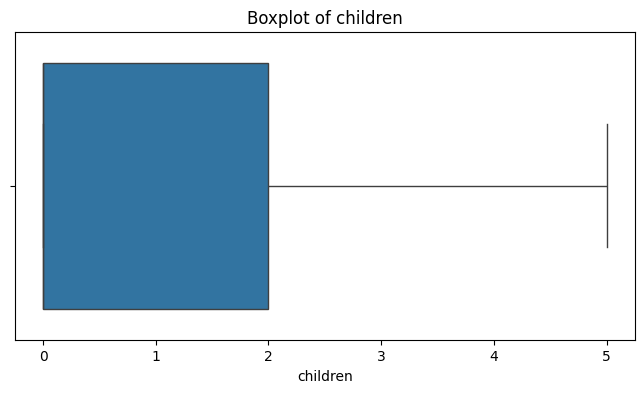

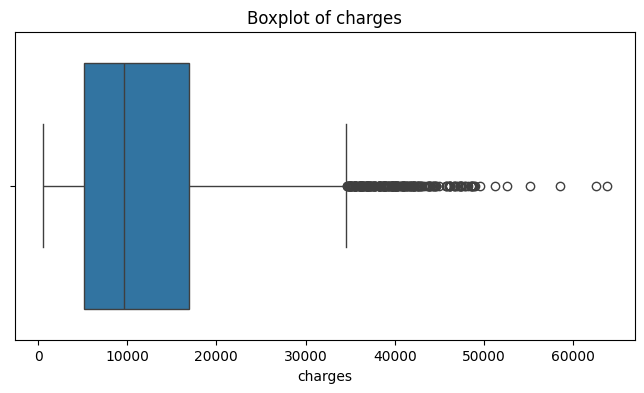

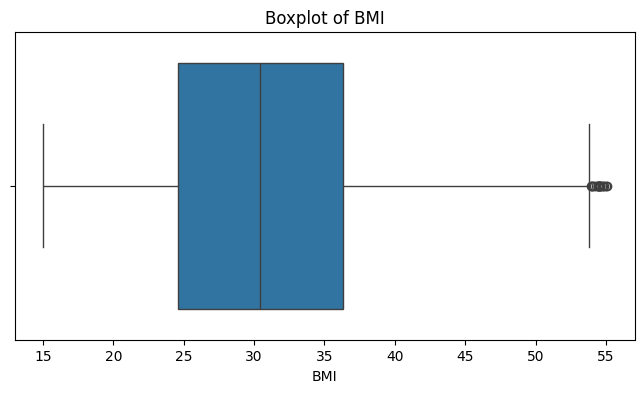

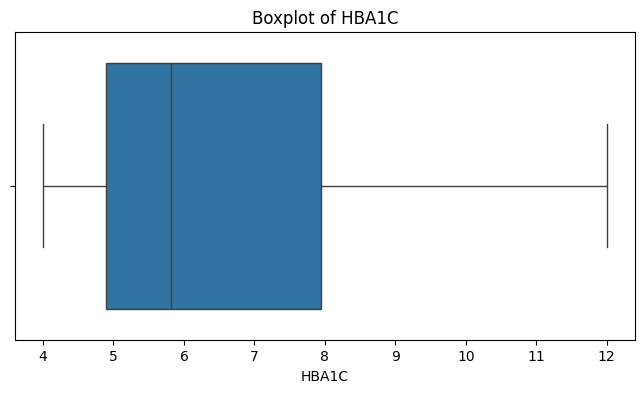

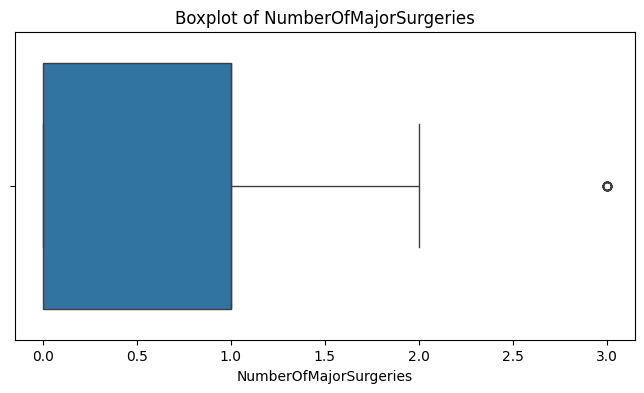

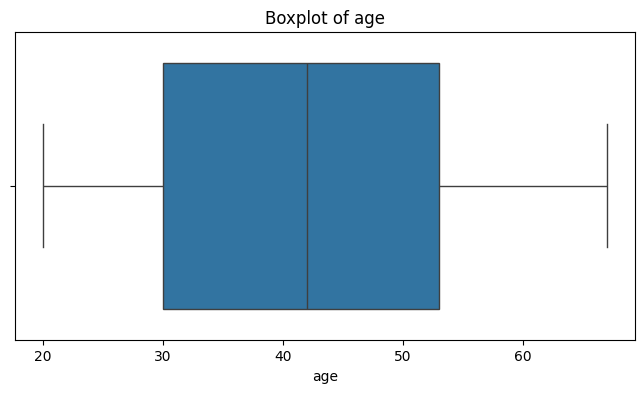

In [441]:
#check for outliers in numerical columns
for col in numcols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=numcols[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

<Axes: ylabel='Density'>

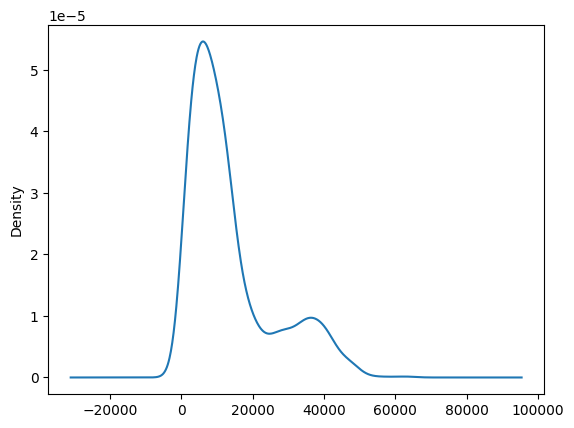

In [442]:
numcols['charges'].plot(kind='density')

Since there are outliers in the numerical columns, we will use RobustScaler for scaling the numerical features.


In [443]:
numcols=numcols.drop(['charges'],axis=1,errors='ignore')
numcols_robust=RobustScaler().fit_transform(numcols)
numcols_robust_df=pd.DataFrame(numcols_robust,columns=numcols.columns)
numcols.head(2)

,children,BMI,HBA1C,NumberOfMajorSurgeries,age
0,0,17.58,4.51,1.0,33.0
1,0,17.60,4.39,1.0,32.0


Since charges are highly positively skewed - Logarthmic or Square Root Transformation is performed to make it more normally distributed for better model performance.

0    563.84
1    570.62
2    600.00
3    604.54
4    637.26
Name: charges, dtype: float64
0    6.334771
1    6.346723
2    6.396930
3    6.404468
4    6.457178
Name: charges, dtype: float64


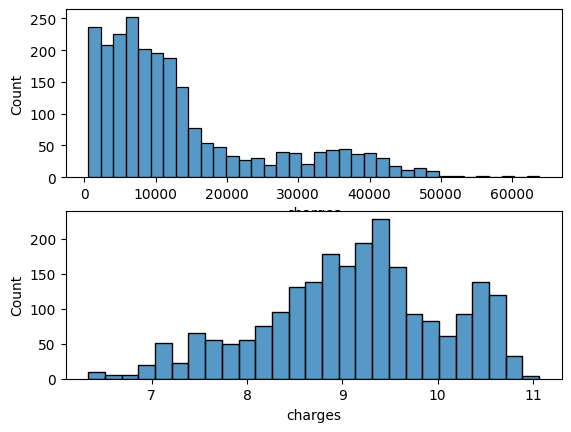

In [444]:
 # Logarthmic Transformation
fig,ax=plt.subplots(2,1)
sns.histplot(merged_df['charges'],ax=ax[0])
sns.histplot(np.log(merged_df['charges']),ax=ax[1])
print(merged_df['charges'].head())
print(np.log(merged_df['charges']).head())

Data Preprocessing. Converting objects columns into numeric. Dummy encoding to ensure equal distribution of data across different variables.
For ordinal categorical variables do label encoding or ordinal encoding and for nominal categorical variables do one hot encoding.

In [445]:
ordinal_cols = ['Hospital tier', 'City tier']
ordinal_col_order=[["tier - 1", "tier - 2", "tier - 3"],["tier - 1", "tier - 2", "tier - 3"]]
encoder=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1,categories=ordinal_col_order)
ordinal_data=encoder.fit_transform(catcols[ordinal_cols])
catcols[ordinal_cols]=ordinal_data
catcols.head()


,Customer ID,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,smoker,name,salutation,gender
0,Id2335,1.0,2.0,R1013,No,No,No,No,"German, Mr. Aaron K",Mr.,Male
1,Id2334,1.0,0.0,R1013,No,No,No,No,"Rosendahl, Mr. Evan P",Mr.,Male
2,Id2333,1.0,0.0,R1013,No,No,Yes,No,"Albano, Ms. Julie",Ms.,Female
3,Id2332,2.0,2.0,R1013,No,No,No,No,"Riveros Gonzalez, Mr. Juan D. Sr.",Mr.,Male
4,Id2331,2.0,2.0,R1013,No,No,No,No,"Brietzke, Mr. Jordan",Mr.,Male


In [446]:
catcols.head()
catcols[['Hospital tier']].value_counts()


Hospital tier
1.0              1334
2.0               691
0.0               300
Name: count, dtype: int64

Converting other categorical columns into numeric by mapping Yes values to 1 and No values to 0. Also gender field male is assigned 0 and famle is assigned 1


In [447]:
binary_map={'Yes':1,'No':0,'yes':1,'No':0,'Male':0,'Female':1}
catcols=catcols.replace(binary_map)
catcols.head()

,Customer ID,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,smoker,name,salutation,gender
0,Id2335,1.0,2.0,R1013,0,0,0,0,"German, Mr. Aaron K",Mr.,0
1,Id2334,1.0,0.0,R1013,0,0,0,0,"Rosendahl, Mr. Evan P",Mr.,0
2,Id2333,1.0,0.0,R1013,0,0,1,0,"Albano, Ms. Julie",Ms.,1
3,Id2332,2.0,2.0,R1013,0,0,0,0,"Riveros Gonzalez, Mr. Juan D. Sr.",Mr.,0
4,Id2331,2.0,2.0,R1013,0,0,0,0,"Brietzke, Mr. Jordan",Mr.,0


In [448]:
catcols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2325 entries, 0 to 2324
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      2325 non-null   object 
 1   Hospital tier    2325 non-null   float64
 2   City tier        2325 non-null   float64
 3   State ID         2325 non-null   object 
 4   Heart Issues     2325 non-null   int64  
 5   Any Transplants  2325 non-null   int64  
 6   Cancer history   2325 non-null   int64  
 7   smoker           2325 non-null   int64  
 8   name             2325 non-null   object 
 9   salutation       2325 non-null   object 
 10  gender           2325 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 199.9+ KB


Checking the state id column for conversion to numeric values

In [449]:
catcols['State ID'].value_counts()

State ID
R1013    609
R1011    574
R1012    572
R1024    159
R1026     84
R1021     70
R1016     64
R1025     40
R1023     38
R1017     36
R1019     26
R1022     14
R1014     13
R1015     11
R1018      9
R1020      6
Name: count, dtype: int64

State ID column has around 16 states. All states are not represented in equal proportions in the data. Creating dummy variables for all regions may also result in too many insignificant predictors.Majority of the patient records are from states R1011, R1012, and R1013. So we can map all other states into a single category for analysis purpose

In [450]:
catcols['State ID']=catcols['State ID'].apply(lambda x: x if x in ['R1011', 'R1012', 'R1013'] else 'Other')
dummies=pd.get_dummies(catcols['State ID'],prefix='State',drop_first=True)
catcols=pd.concat([catcols,dummies],axis=1)
catcols.head()


,Customer ID,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,smoker,name,salutation,gender,State_R1011,State_R1012,State_R1013
0,Id2335,1.0,2.0,R1013,0,0,0,0,"German, Mr. Aaron K",Mr.,0,False,False,True
1,Id2334,1.0,0.0,R1013,0,0,0,0,"Rosendahl, Mr. Evan P",Mr.,0,False,False,True
2,Id2333,1.0,0.0,R1013,0,0,1,0,"Albano, Ms. Julie",Ms.,1,False,False,True
3,Id2332,2.0,2.0,R1013,0,0,0,0,"Riveros Gonzalez, Mr. Juan D. Sr.",Mr.,0,False,False,True
4,Id2331,2.0,2.0,R1013,0,0,0,0,"Brietzke, Mr. Jordan",Mr.,0,False,False,True


In [451]:
catcols.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2325 entries, 0 to 2324
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      2325 non-null   object 
 1   Hospital tier    2325 non-null   float64
 2   City tier        2325 non-null   float64
 3   State ID         2325 non-null   object 
 4   Heart Issues     2325 non-null   int64  
 5   Any Transplants  2325 non-null   int64  
 6   Cancer history   2325 non-null   int64  
 7   smoker           2325 non-null   int64  
 8   name             2325 non-null   object 
 9   salutation       2325 non-null   object 
 10  gender           2325 non-null   int64  
 11  State_R1011      2325 non-null   bool   
 12  State_R1012      2325 non-null   bool   
 13  State_R1013      2325 non-null   bool   
dtypes: bool(3), float64(2), int64(5), object(4)
memory usage: 206.7+ KB


Hypothesis Testing

Null Hypothesis(Ho): The average hospitalization costs for the three types of hospitals are not significantly different.
Alt Hypothesis(H1):  There is significant difference in the average hospitalization cost for atleast one of the hospital type.
Since there are more than two tiers we will be using One-way Anova to test the hypothesis

In [452]:
print("Mean hospital charges",merged_df['charges'].groupby(merged_df['Hospital tier']).mean() )
print('Variance of charges',merged_df['charges'].groupby(merged_df['Hospital tier']).var())

Mean hospital charges Hospital tier
tier - 1    30131.995900
tier - 2    11875.883861
tier - 3     9487.456223
Name: charges, dtype: float64
Variance of charges Hospital tier
tier - 1    1.475828e+08
tier - 2    1.276524e+08
tier - 3    2.198192e+07
Name: charges, dtype: float64


In [453]:
merged_df['Hospital tier'].unique()

array(['tier - 2', 'tier - 3', 'tier - 1'], dtype=object)

In [454]:
 # Split Data into groups based on hospital tier
tier_1 = merged_df[merged_df['Hospital tier'] == 'tier - 1']['charges']
tier_2 = merged_df[merged_df['Hospital tier'] == 'tier - 2']['charges']    
tier_3 = merged_df[merged_df['Hospital tier'] == 'tier - 3']['charges']

f_stat, p_value = f_oneway(tier_1, tier_2, tier_3)
print("F-statistic:", f_stat)
print("P-value:", p_value)

# Interpret result
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: At least one hospital tier has a significantly different average cost.")
else:
    print("Fail to reject the null hypothesis: The average costs across hospital tiers are not significantly different.")

F-statistic: 493.98956631117625
P-value: 1.7738221310852664e-179
Reject the null hypothesis: At least one hospital tier has a significantly different average cost.


As per the ANOVA test results, since the p-value is less than the significance level of 0.05, we reject the null hypothesis.
This indicates that there is a significant difference in the average hospitalization costs among at least one of the hospital tiers.

Null Hypothesis(Ho): The average hospitalization costs for the three types of cities are not significantly different
Alt Hypothesis(H1):  There is significant difference in the average hospitalization cost for atleast one of the city type.
Since there are more than two tiers we will be using One-way Anova to test the hypothesis

In [455]:
print("Mean hospital charges",merged_df['charges'].groupby(merged_df['City tier']).mean() )
print('Variance of charges',merged_df['charges'].groupby(merged_df['City tier']).var())

Mean hospital charges City tier
tier - 1    13009.972579
tier - 2    13471.919281
tier - 3    14045.312066
Name: charges, dtype: float64
Variance of charges City tier
tier - 1    1.212273e+08
tier - 2    1.462938e+08
tier - 3    1.529314e+08
Name: charges, dtype: float64


In [456]:
 # Split Data into groups based on city tier
city_tier_1 = merged_df[merged_df['City tier'] == 'tier - 1']['charges']
city_tier_2 = merged_df[merged_df['City tier'] == 'tier - 2']['charges']    
city_tier_3 = merged_df[merged_df['City tier'] == 'tier - 3']['charges']

f_stat, p_value = f_oneway(city_tier_1, city_tier_2, city_tier_3)
print("F-statistic:", f_stat)
print("P-value:", p_value)

# Interpret result
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: At least one city tier has a significantly different average cost.")
else:
    print("Fail to reject the null hypothesis: The average costs across city tiers are not significantly different.")

F-statistic: 1.454355756181469
P-value: 0.23376344386881315
Fail to reject the null hypothesis: The average costs across city tiers are not significantly different.


As per the ANOVA test results, since the p-value is less than the significance level of 0.05, we reject the null hypothesis.
This indicates that there is a significant difference in the average hospitalization costs among at least one of the hospital tiers. 

Null Hypothesis(Ho):  The average hospitalization cost for smokers is not significantly different from the average cost 
for nonsmokers.
Alt Hypothesis(H1):  There is significant difference in the average hospitalization cost for smokers and non-smokers.

Here we are comparing mean of charges between smoker and non-smoker so we will be using Independent two smaple t-test.

In [457]:
merged_df['charges'].groupby(merged_df['smoker']).mean()  


smoker
No      8409.199250
yes    32866.960226
Name: charges, dtype: float64

In [458]:
merged_df['charges'].groupby(merged_df['smoker']).var()  

smoker
No     3.081109e+07
yes    8.352025e+07
Name: charges, dtype: float64

In [459]:
# Split Data into groups based on smoker status
smokers = merged_df[merged_df['smoker'] == 'yes']['charges']
nonsmokers = merged_df[merged_df['smoker'] == 'No']['charges']
t_stat, p_value =ttest_ind(smokers, nonsmokers,equal_var=False)
# Print results
print("T-statistic:", t_stat)
print("P-value:", p_value)

# Interpret result
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Average hospitalization costs are significantly different between smokers and nonsmokers.")
else:
    print("Fail to reject the null hypothesis: Average hospitalization costs are not significantly different between smokers and nonsmokers.")


T-statistic: 56.316832285932286
P-value: 6.697431845033993e-238
Reject the null hypothesis: Average hospitalization costs are significantly different between smokers and nonsmokers.


As per the ANOVA test results, since the p-value is less than the significance level of 0.05, we reject the null hypothesis.
This indicates that there is a significant difference in the average hospitalization costs among at least one of the hospital tiers. 

Null Hypothesis: Smoking and heart issues are independent.
Alt Hypothesis: Smoking and Heart Issues are dependent .
In this hypothesis both variables are independent and categorical so we are using Chi-square test of Independence.


In [460]:
pd.crosstab(merged_df['smoker'], merged_df['Heart Issues'])

Heart Issues,No,yes
smoker,,
No,1108,731
yes,297,189


In [461]:
# Create a contingency table
contingency_table = pd.crosstab(merged_df['smoker'], merged_df['Heart Issues'])
chi2, p, dof, expected = chi2_contingency(contingency_table)
print("Chi-square statistic:", chi2)
print("P-value:", p)    
# Interpret result
alpha = 0.05
if p < alpha:
    print("Reject the null hypothesis: Smoking and heart issues are dependent.")
else:
    print("Fail to reject the null hypothesis: Smoking and heart issues are independent.")


Chi-square statistic: 0.08588150449910657
P-value: 0.7694797581780767
Fail to reject the null hypothesis: Smoking and heart issues are independent.


As per the ANOVA test results, since the p-value is less than the significance level of 0.05, we reject the null hypothesis. 
This indicates that there is a significant difference in the average hospitalization costs among at least one of the hospital tiers.

Combining numerical and categorical data into final dataset

In [462]:
#Combined numerical and categorical data
final_df=pd.concat([numcols_robust_df,catcols],axis=1)
final_df.head(2)

,children,BMI,HBA1C,NumberOfMajorSurgeries,age,Customer ID,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,smoker,name,salutation,gender,State_R1011,State_R1012,State_R1013
0,0.0,-1.096195,-0.426230,0.0,-0.391304,Id2335,1.0,2.0,R1013,0,0,0,0,"German, Mr. Aaron K",Mr.,0,False,False,True
1,0.0,-1.094485,-0.465574,0.0,-0.434783,Id2334,1.0,0.0,R1013,0,0,0,0,"Rosendahl, Mr. Evan P",Mr.,0,False,False,True


In [463]:
#Adding charges column(dependent variable) to final_df
final_df_with_charges=pd.concat([final_df,merged_df['charges']],axis=1)
final_df_with_charges.head(2)

,children,BMI,HBA1C,NumberOfMajorSurgeries,age,Customer ID,Hospital tier,City tier,State ID,Heart Issues,Any Transplants,Cancer history,smoker,name,salutation,gender,State_R1011,State_R1012,State_R1013,charges
0,0.0,-1.096195,-0.426230,0.0,-0.391304,Id2335,1.0,2.0,R1013,0,0,0,0,"German, Mr. Aaron K",Mr.,0,False,False,True,563.84
1,0.0,-1.094485,-0.465574,0.0,-0.434783,Id2334,1.0,0.0,R1013,0,0,0,0,"Rosendahl, Mr. Evan P",Mr.,0,False,False,True,570.62


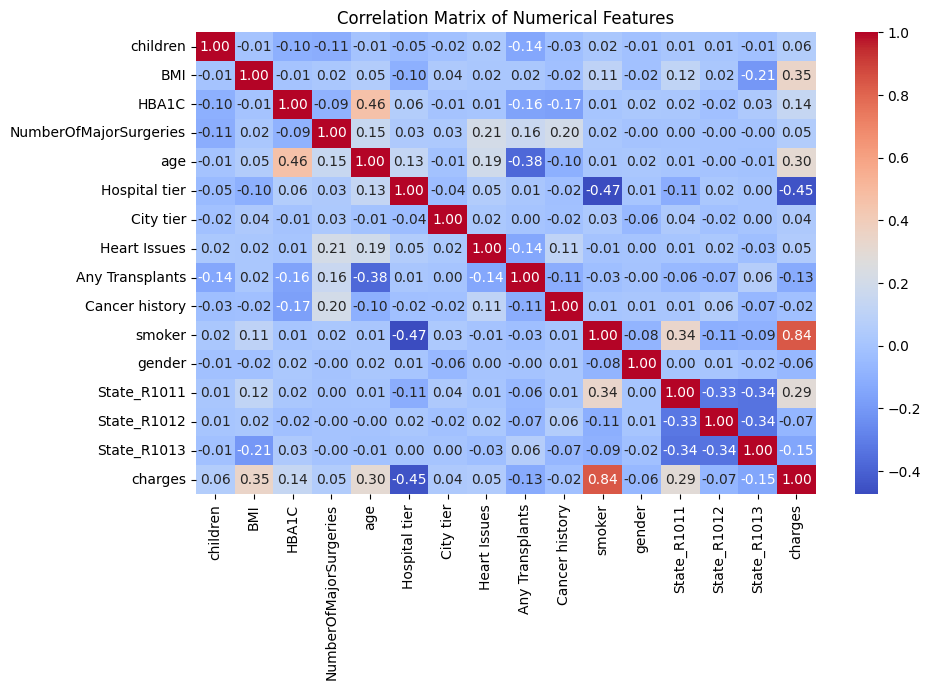

In [464]:
#Creating a heat map to see correlation between numerical variables
corr_df=final_df_with_charges.drop(['Customer ID','name','State ID','salutation'],axis=1,errors='ignore')
plt.figure(figsize=(10, 6)) 
correlation_matrix = corr_df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')       
plt.show()


Based on the correlation matrix inference are as follows:
1)Smokers have a strong positive correlation(0.84) with healthcare charges, indicating that smoking is associated with higher hospitalization costs.
2)There is a moderate positive correlation(0.35) between BMI and healthcare charges, indicating that higher BMI may be associated with slightly increased hospitalization costs.
3)Age also has a moderate positive correlation(0.3) with healthcare charges, suggesting that older individuals tend to incur higher hospitalization costs.
4) Hospital tier has a negative correlation with charges but this is because we have encoded tier-1(the best) as 0 and tier-3(the worst) as 2. So best hospitals have highest charges and lower tiers  has the lowest charges.
5)Transplants,HBA1C(diabetic indicator) have a weak positive correlation with charges indicating that people with transplants or diabetes tend to have slightly higher hospitalization costs.
                                                       




Here the dependent variable is 'charges' which is numeric and continuous. So this is a regression problem. 
There is no multicollinearity as there is no high correlation between independent variables. So let us build a regression model to predict healthcare costs.

In [465]:
y=final_df_with_charges['charges']
x=final_df_with_charges.drop(['charges','Customer ID','name','State ID','salutation'],axis=1,errors='ignore')
y.head(), x.head()

(0    563.84
 1    570.62
 2    600.00
 3    604.54
 4    637.26
 Name: charges, dtype: float64,
    children       BMI     HBA1C  NumberOfMajorSurgeries       age  \
 0       0.0 -1.096195 -0.426230                     0.0 -0.391304   
 1       0.0 -1.094485 -0.465574                     0.0 -0.434783   
 2       0.0 -1.191107  0.177049                     0.0 -0.434783   
 3       0.0 -1.085934  0.154098                     0.0 -0.434783   
 4       0.0 -0.689183 -0.078689                     0.0 -0.652174   
 
    Hospital tier  City tier  Heart Issues  Any Transplants  Cancer history  \
 0            1.0        2.0             0                0               0   
 1            1.0        0.0             0                0               0   
 2            1.0        0.0             0                0               1   
 3            2.0        2.0             0                0               0   
 4            2.0        2.0             0                0               0   
 
    s

In [466]:
#Since our data is imbalanced, we will create stratified bins for regression
#Create stratified bins for regression
n_bins = 10
y_binned = pd.qcut(y, q=n_bins, labels=False, duplicates='drop')

In [467]:
final_df.columns

Index(['children', 'BMI', 'HBA1C', 'NumberOfMajorSurgeries', 'age',
       'Customer ID', 'Hospital tier', 'City tier', 'State ID', 'Heart Issues',
       'Any Transplants', 'Cancer history', 'smoker', 'name', 'salutation',
       'gender', 'State_R1011', 'State_R1012', 'State_R1013'],
      dtype='object')

In [468]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_split = list(skf.split(x, y_binned))

In [469]:
#Adding fold column to the dataframe
final_df_with_charges['fold'] = -1
for fold, (_, val_idx) in enumerate(skf.split(x, y_binned)):
    final_df_with_charges.loc[val_idx, 'fold'] = fold

In [470]:
# Linear Regression Pipeline
lin_pipeline = Pipeline([
    ('linreg', LinearRegression())
])
# Ridge Regression Pipeline
ridge_pipeline = Pipeline([
        ('ridge', Ridge())
])

ridge_params = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(ridge_pipeline, ridge_params, cv=cv_split,
                          scoring='neg_root_mean_squared_error')

# Gradient Boosting Regressor Pipeline
gbr_pipeline = Pipeline([
    ('gbr', GradientBoostingRegressor(random_state=42))
])
gb_params = {
    'gbr__n_estimators': [100, 200],
    'gbr__max_depth': [3, 5],
    'gbr__learning_rate': [0.05, 0.1]
}

gb_grid = GridSearchCV(gbr_pipeline, gb_params, cv=cv_split,
                       scoring='neg_root_mean_squared_error')

In [471]:
#Training and evaluating models using Stratified K-Fold Cross-Validation
lin_scores = []
for train_idx, val_idx in skf.split(x, y_binned):
    x_train, x_val = x.iloc[train_idx], x.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

model = clone(lin_pipeline)
model.fit(x_train, y_train)
preds = model.predict(x_val)


rmse = root_mean_squared_error(y_val, preds)
lin_scores.append(rmse)

print("Linear Regression CV RMSE:", np.mean(lin_scores))

Linear Regression CV RMSE: 4765.001294547506


In [472]:
# Ridge Regression
ridge_grid.fit(x, y)
print("Best Ridge Alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Best Ridge Alpha: {'ridge__alpha': 1}
Best Ridge CV RMSE: 4477.692467570811


In [473]:
# Gradient Boosting
gb_grid.fit(x, y)
print("Best GB Params:", gb_grid.best_params_)
print("Best GB CV RMSE:", -gb_grid.best_score_)

Best GB Params: {'gbr__learning_rate': 0.05, 'gbr__max_depth': 5, 'gbr__n_estimators': 100}
Best GB CV RMSE: 3427.816670683614


From above models  GradientBoostingRegressor is performing better than other 2 models. Let us check the model performance on test data

In [474]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
# Final evaluation on test set using the best model (Gradient Boosting)
best_model = clone(gb_grid.best_estimator_)
best_model.fit(x_train, y_train)
test_preds = best_model.predict(x_test) 
test_rmse = root_mean_squared_error(y_test, test_preds)
print("Test RMSE of the best model (Gradient Boosting):", test_rmse)    

Test RMSE of the best model (Gradient Boosting): 3745.692979049326


In [475]:
#Variable importance from Gradient Boosting model
best_gb_model = gb_grid.best_estimator_.named_steps['gbr']
feature_importances = best_gb_model.feature_importances_
features = x.columns
importance_df = pd.DataFrame({'Feature': features, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)
print(importance_df)

                   Feature  Importance
10                  smoker    0.734780
1                      BMI    0.117880
4                      age    0.090032
5            Hospital tier    0.019134
0                 children    0.011896
12             State_R1011    0.007499
14             State_R1013    0.007154
2                    HBA1C    0.006773
11                  gender    0.002476
6                City tier    0.000842
13             State_R1012    0.000654
7             Heart Issues    0.000340
9           Cancer history    0.000320
3   NumberOfMajorSurgeries    0.000195
8          Any Transplants    0.000021


From feature_importances we could see that smoker, BMI and age are the top 3 important features.

Estimate the cost of hospitalization for Christopher, Ms. Jayna (Date of 
birth 12/28/1988; height 170 cm; and weight 85 kgs). She lives with her partner and two children 
in a tier-1 city, and her state’s State ID is R1011. She was found to be nondiabetic (HbA1c = 5.8). 
She smokes but is otherwise healthy. She has had no transplants or major surgeries. Her father 
died of lung cancer. Hospitalization costs will be estimated using tier-1 hospitals

In [476]:
#Creating a dataframe with new patient details
new_patient_data = {
    'birthdate': ['1988-12-28'],
    'Height': [170],
    'Weight': [85],
    'children': [2],
    'HBA1C': [5.8],
    'NumberOfMajorSurgeries': [0], 
    'Hospital tier': [0],
    'City tier': [0],
    'Heart Issues': [0],  # No
    'Any Transplants': [0],  # No
    'Cancer history': [1],  # No
    'smoker': [1],  # Yes
    'State_R1012': [0],
    'State_R1013': [0],
    'State_R1011': [1],
    'gender': [1]
}


In [477]:
#Calculating age from birthdate
new_patient_data['birthdate'] = pd.to_datetime(new_patient_data['birthdate'])
today = pd.to_datetime(date.today())    
new_patient_data['age'] = (today.year - new_patient_data['birthdate'].year) - (
    (today.month < (new_patient_data['birthdate'].month)) | ((today.month == new_patient_data['birthdate'].month) & (today.day < new_patient_data['birthdate'].day))
)
new_patient_df = pd.DataFrame(new_patient_data)
new_patient_df.head(2)

,birthdate,Height,Weight,children,HBA1C,NumberOfMajorSurgeries,Hospital tier,City tier,Heart Issues,Any Transplants,Cancer history,smoker,State_R1012,State_R1013,State_R1011,gender,age
0,1988-12-28,170,85,2,5.8,0,0,0,0,0,1,1,0,0,1,1,36


In [478]:
#calculating bmi from height and weight
new_patient_df['BMI'] = new_patient_df['Weight'] / ((new_patient_df['Height'] / 100) ** 2)
new_patient_df.head(2)

,birthdate,Height,Weight,children,HBA1C,NumberOfMajorSurgeries,Hospital tier,City tier,Heart Issues,Any Transplants,Cancer history,smoker,State_R1012,State_R1013,State_R1011,gender,age,BMI
0,1988-12-28,170,85,2,5.8,0,0,0,0,0,1,1,0,0,1,1,36,29.411765


In [479]:
new_patient_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   birthdate               1 non-null      datetime64[ns]
 1   Height                  1 non-null      int64         
 2   Weight                  1 non-null      int64         
 3   children                1 non-null      int64         
 4   HBA1C                   1 non-null      float64       
 5   NumberOfMajorSurgeries  1 non-null      int64         
 6   Hospital tier           1 non-null      int64         
 7   City tier               1 non-null      int64         
 8   Heart Issues            1 non-null      int64         
 9   Any Transplants         1 non-null      int64         
 10  Cancer history          1 non-null      int64         
 11  smoker                  1 non-null      int64         
 12  State_R1012             1 non-null      int64         

In [480]:
num_cols=['children', 'NumberOfMajorSurgeries', 'HBA1C', 'age', 'BMI']
train_mean=x[num_cols].mean()
traing_std=x[num_cols].std()
new_patient_df[num_cols] = (new_patient_df[num_cols] - train_mean) / traing_std


In [481]:
new_patient_df=new_patient_df.drop(['birthdate','Height','Weight'],axis=1,errors='ignore')


In [482]:
feature_order=x.columns
new_patient_df=new_patient_df[feature_order]
new_patient_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   children                1 non-null      float64
 1   BMI                     1 non-null      float64
 2   HBA1C                   1 non-null      float64
 3   NumberOfMajorSurgeries  1 non-null      float64
 4   age                     1 non-null      float64
 5   Hospital tier           1 non-null      int64  
 6   City tier               1 non-null      int64  
 7   Heart Issues            1 non-null      int64  
 8   Any Transplants         1 non-null      int64  
 9   Cancer history          1 non-null      int64  
 10  smoker                  1 non-null      int64  
 11  gender                  1 non-null      int64  
 12  State_R1011             1 non-null      int64  
 13  State_R1012             1 non-null      int64  
 14  State_R1013             1 non-null      int64 

In [483]:
#Predicting healthcare charges for the new patient using the best model (Gradient Boosting)
predicted_charges=gb_grid.predict(new_patient_df)
print(predicted_charges)


[47705.76782341]


From above estimated charges for new patient is around 47705 USD